# Plotting from pandas DataFrame - Part I, II

In [12]:
import pandas as pd
import numpy as np 
%matplotlib inline
import matplotlib.pyplot as plt

In [13]:
car_sales = pd.read_csv("cars_dataset.csv")
car_sales[:10]

,Make,Colour,Odometer (km),Doors,Price (INR)
0,Mercedes-Benz GLC,Black,6556,4,2923000
1,Volkswagen Virtus,Black,177392,4,605000
2,Ford Mustang,White,7811,3,717000
3,Honda Civic,Green,52124,4,1368000
4,Tesla Model 3,Brown,154472,4,1573000
5,BMW 3 Series,Pearl White,89194,4,3469000
6,Maruti Suzuki Swift,Black,24312,4,1065000
7,BMW 5 Series,Blue,211583,2,2900000
8,MG Hector,Black,144714,4,2258000
9,Kia Seltos,Yellow,50407,4,416000


<Axes: >

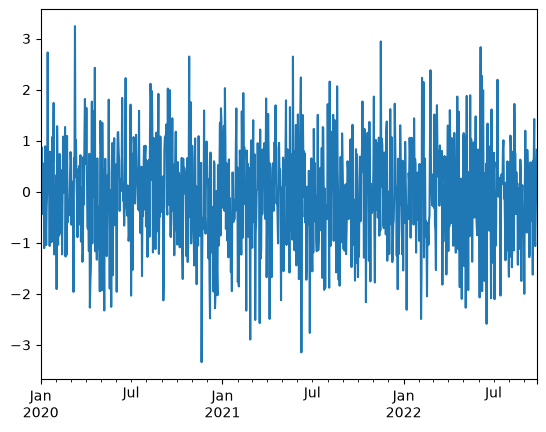

In [34]:
ts = pd.Series(np.random.randn(1000),
               index=pd.date_range("1/1/2020", periods=1000))
ts.cumsum
ts.plot()

In [20]:
numbers = np.random.randn(1000)
numbers

array([-6.08886661e-01,  5.22040229e-01, -2.10086092e-01, -7.43267548e-01,
       -1.91464670e+00, -4.98244170e-01, -1.57125511e+00,  4.96630243e-01,
       -5.50162117e-01,  5.68161512e-01,  5.82190105e-02,  1.78969853e+00,
        3.21342244e+00, -1.85020498e+00,  6.59780822e-01,  7.62820682e-01,
        2.13345045e-01,  5.04688392e-01, -3.82188995e-01, -1.43173641e+00,
       -2.69947908e+00, -1.66214529e+00, -1.47666661e+00,  5.39252585e-01,
       -8.10576593e-01,  1.82753446e-01,  1.23619471e+00, -1.01095738e+00,
       -5.02996592e-01, -1.58150737e+00, -3.51699682e-01, -9.00652096e-01,
       -1.88182094e-01, -2.40918279e-01,  1.49680989e+00,  1.21908556e+00,
       -1.01256138e-02,  7.71044746e-02, -1.28528434e+00, -3.77225329e-01,
       -4.47736506e-01,  5.22250286e-02,  4.24620383e-02, -2.70888390e-02,
        8.36137587e-01, -1.23867247e+00, -1.13447766e+00, -2.58054704e-01,
        8.16356044e-01, -1.21971428e+00,  1.63207005e+00,  8.99109380e-01,
        5.95432338e-01, -

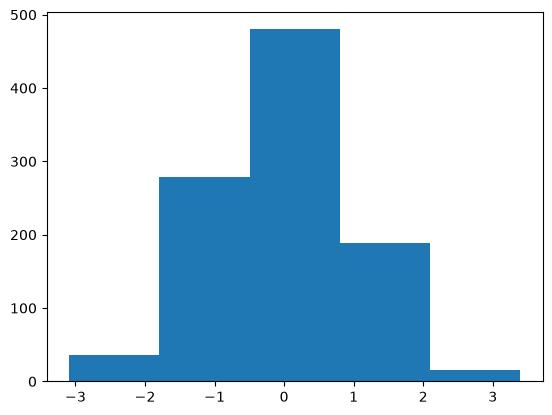

In [23]:
plt.hist(numbers, bins=5)
plt.show()

In [35]:
car_sales

,Make,Colour,Odometer (km),Doors,Price (INR)
0,Mercedes-Benz GLC,Black,6556,4,2923000
1,Volkswagen Virtus,Black,177392,4,605000
2,Ford Mustang,White,7811,3,717000
3,Honda Civic,Green,52124,4,1368000
4,Tesla Model 3,Brown,154472,4,1573000
...,...,...,...,...,...
495,Toyota RAV4,Black,77445,4,794000
496,Kia Carens,Silver,91312,4,1036000
497,Kia Sonet,Brown,91304,4,978000
498,Porsche Macan,Red,17609,4,4913000


# Plotting from pandas DataFrame - Part II

In [36]:
# Let's do something fun, first.

car_sales["Price (INR)"] = car_sales["Price (INR)"].apply(lambda x:"₹" + format(x, ","))

In [37]:
car_sales

,Make,Colour,Odometer (km),Doors,Price (INR)
0,Mercedes-Benz GLC,Black,6556,4,"₹2,923,000"
1,Volkswagen Virtus,Black,177392,4,"₹605,000"
2,Ford Mustang,White,7811,3,"₹717,000"
3,Honda Civic,Green,52124,4,"₹1,368,000"
4,Tesla Model 3,Brown,154472,4,"₹1,573,000"
...,...,...,...,...,...
495,Toyota RAV4,Black,77445,4,"₹794,000"
496,Kia Carens,Silver,91312,4,"₹1,036,000"
497,Kia Sonet,Brown,91304,4,"₹978,000"
498,Porsche Macan,Red,17609,4,"₹4,913,000"


In [43]:
car_sales["Price (INR)"] = car_sales["Price (INR)"].str.replace(r'[₹,]', '', regex=True).astype(int)
car_sales

,Make,Colour,Odometer (km),Doors,Price (INR)
0,Mercedes-Benz GLC,Black,6556,4,2923000
1,Volkswagen Virtus,Black,177392,4,605000
2,Ford Mustang,White,7811,3,717000
3,Honda Civic,Green,52124,4,1368000
4,Tesla Model 3,Brown,154472,4,1573000
...,...,...,...,...,...
495,Toyota RAV4,Black,77445,4,794000
496,Kia Carens,Silver,91312,4,1036000
497,Kia Sonet,Brown,91304,4,978000
498,Porsche Macan,Red,17609,4,4913000


In [49]:
type(car_sales['Price (INR)'])

pandas.Series

In [50]:
# # Now let's remove the last 2 zeros.
# car_sales["Price (INR)"] = car_sales["Price (INR)"].str[:-2]

AttributeError: Can only use .str accessor with string values, not integer

In [52]:
 car_sales["Sale Date"] = pd.date_range("1/1/2025", periods=len(car_sales))

In [59]:
car_sales["Total Sales"] = car_sales["Price (INR)"].cumsum()

In [60]:
car_sales

,Make,Colour,Odometer (km),Doors,Price (INR),Sale Date,Total Sales
0,Mercedes-Benz GLC,Black,6556,4,2923000,2025-01-01,2923000
1,Volkswagen Virtus,Black,177392,4,605000,2025-01-02,3528000
2,Ford Mustang,White,7811,3,717000,2025-01-03,4245000
3,Honda Civic,Green,52124,4,1368000,2025-01-04,5613000
4,Tesla Model 3,Brown,154472,4,1573000,2025-01-05,7186000
...,...,...,...,...,...,...,...
495,Toyota RAV4,Black,77445,4,794000,2026-05-11,749423000
496,Kia Carens,Silver,91312,4,1036000,2026-05-12,750459000
497,Kia Sonet,Brown,91304,4,978000,2026-05-13,751437000
498,Porsche Macan,Red,17609,4,4913000,2026-05-14,756350000


In [57]:
car_sales["Price (INR)"][0].dtype

dtype('int64')

## Let's plot the total sales

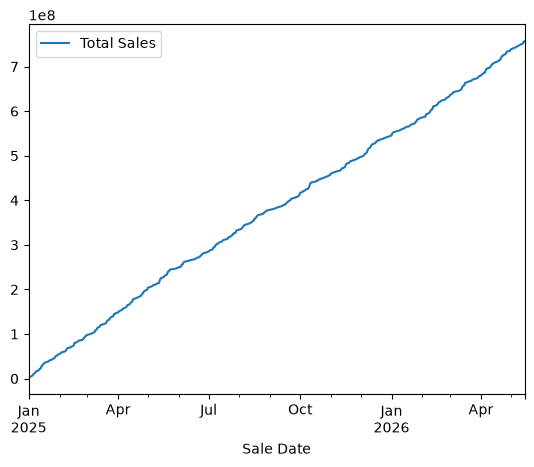

In [61]:
car_sales.plot(x="Sale Date", y="Total Sales");

<Axes: xlabel='Sale Date', ylabel='Total Sales'>

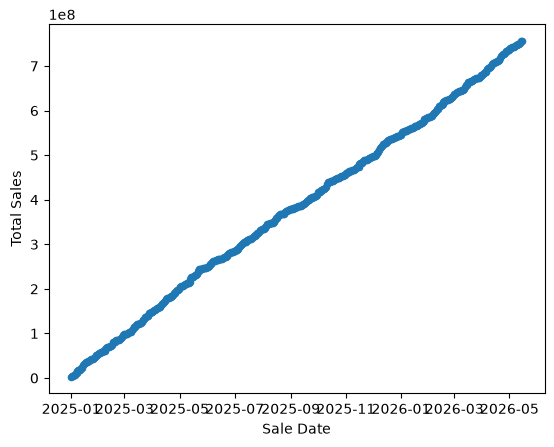

In [64]:
car_sales.plot(x="Sale Date", y="Total Sales", kind="scatter")

In [66]:
car_sales

,Make,Colour,Odometer (km),Doors,Price (INR),Sale Date,Total Sales
0,Mercedes-Benz GLC,Black,6556,4,2923000,2025-01-01,2923000
1,Volkswagen Virtus,Black,177392,4,605000,2025-01-02,3528000
2,Ford Mustang,White,7811,3,717000,2025-01-03,4245000
3,Honda Civic,Green,52124,4,1368000,2025-01-04,5613000
4,Tesla Model 3,Brown,154472,4,1573000,2025-01-05,7186000
...,...,...,...,...,...,...,...
495,Toyota RAV4,Black,77445,4,794000,2026-05-11,749423000
496,Kia Carens,Silver,91312,4,1036000,2026-05-12,750459000
497,Kia Sonet,Brown,91304,4,978000,2026-05-13,751437000
498,Porsche Macan,Red,17609,4,4913000,2026-05-14,756350000


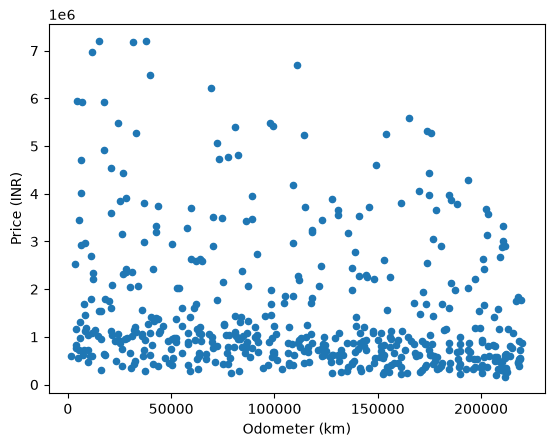

In [68]:
car_sales.plot(x="Odometer (km)", y="Price (INR)", kind="scatter");

In [69]:
car_sales

,Make,Colour,Odometer (km),Doors,Price (INR),Sale Date,Total Sales
0,Mercedes-Benz GLC,Black,6556,4,2923000,2025-01-01,2923000
1,Volkswagen Virtus,Black,177392,4,605000,2025-01-02,3528000
2,Ford Mustang,White,7811,3,717000,2025-01-03,4245000
3,Honda Civic,Green,52124,4,1368000,2025-01-04,5613000
4,Tesla Model 3,Brown,154472,4,1573000,2025-01-05,7186000
...,...,...,...,...,...,...,...
495,Toyota RAV4,Black,77445,4,794000,2026-05-11,749423000
496,Kia Carens,Silver,91312,4,1036000,2026-05-12,750459000
497,Kia Sonet,Brown,91304,4,978000,2026-05-13,751437000
498,Porsche Macan,Red,17609,4,4913000,2026-05-14,756350000


<Axes: xlabel='Colour', ylabel='Price (INR)'>

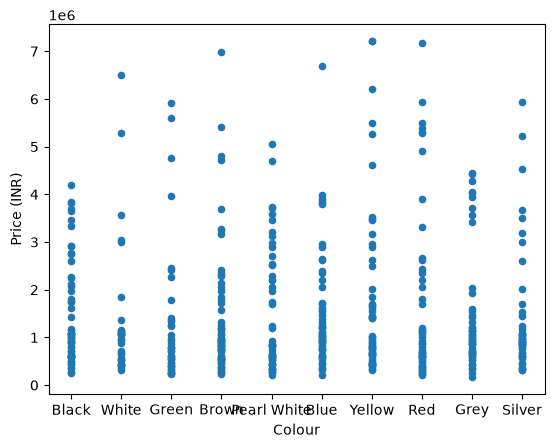

In [71]:
car_sales.plot(x="Colour", y="Price (INR)", kind="scatter")

In [72]:
car_sales

,Make,Colour,Odometer (km),Doors,Price (INR),Sale Date,Total Sales
0,Mercedes-Benz GLC,Black,6556,4,2923000,2025-01-01,2923000
1,Volkswagen Virtus,Black,177392,4,605000,2025-01-02,3528000
2,Ford Mustang,White,7811,3,717000,2025-01-03,4245000
3,Honda Civic,Green,52124,4,1368000,2025-01-04,5613000
4,Tesla Model 3,Brown,154472,4,1573000,2025-01-05,7186000
...,...,...,...,...,...,...,...
495,Toyota RAV4,Black,77445,4,794000,2026-05-11,749423000
496,Kia Carens,Silver,91312,4,1036000,2026-05-12,750459000
497,Kia Sonet,Brown,91304,4,978000,2026-05-13,751437000
498,Porsche Macan,Red,17609,4,4913000,2026-05-14,756350000


<Axes: ylabel='Frequency'>

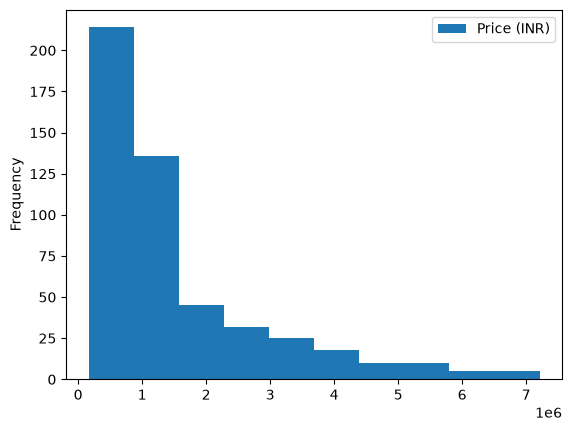

In [77]:
car_sales.plot(x="Make", y="Price (INR)", kind="hist")